# Modular pipeline: PDB → density → ice → crowding → scattering → optics → detector

The other notebooks in `demo-notebooks/` (`create_particle_stack/`,
`create_micrograph/`, `create_tilt_series/`) use SPECTER's image-formation
objects (`specter.imaging`): a `Specimen` is scattered into an `ExitWave`,
the lens applies its transfer function, and the camera records an `Image`.
Those objects own the bookkeeping between stages (padding, the defocus
reference plane, the image grid, per-image seeds) and call the engine
modules underneath: `PotentialBuilder`, `IceBank`/`RandomIcemaker`,
`CrowdWithDuplicates`, `Scattering`, `Aberration` and `Detector`.

This notebook builds the **same physical pipeline from those engines**, one
stage per section, calling each module directly. It shows what the objects
do under the hood, and that each piece is an ordinary, independently usable
`torch.nn.Module`: the place to start when changing a stage's physics.

Pipeline (the order `Specimen.scatter` and its successors apply, in
`imaging/_specimen.py` and `imaging/_waves.py`):

```
PDB file
  └─ atomic coordinates            (specter.pdb.PDB)
      └─ 3D scattering potential    (specter.potential.PotentialBuilder)
          └─ posed batch (rotate)   (specter.rotations.VolumeRotator)
              └─ + crowding         (specter.crowding.CrowdWithDuplicates)
                  └─ + amorphous ice (specter.ice: IceBank / RandomIcemaker)
                      └─ exit wave   (specter.scattering.Scattering)
                          └─ aberrated exit wave  (specter.aberrations.Aberration)
                              └─ detector image    (specter.microscope.Detector)
```

All parameters live in [`particle_stack_generator_modular.toml`](./particle_stack_generator_modular.toml),
loaded below via `load_config`, the same TOML-driven convention as the other
demo notebooks. Edit that file, not this notebook, to change the structure,
box size, dose, defocus range, etc.

In [1]:
import logging

import matplotlib.pyplot as plt
import roma
import torch

import specter
from specter import rotations
from specter.config import load_config, parse_scalar_or_range
from specter.image import normalize_particles
from specter.arrays import compute_nz, pad_volume
from specter.pdb import PDB
from specter.plots import plot3d
from specter.potential import PotentialBuilder
from specter.crowding import CrowdWithDuplicates
from specter.ice import blend_ice_into_volume, resolve_icemaker
from specter.scattering import Scattering
from specter.aberrations import (
    Aberration,
    aberration_model_for_scattering,
    defocus_midplane_shift,
)
from specter.microscope import Detector
from specter.rotations import VolumeRotator

In [2]:
config = load_config("particle_stack_generator_modular.toml")

In [3]:
specter.set_verbosity(logging.INFO)
device = config.device
device

'cuda:0'

## 1. PDB → atomic coordinates

`specter.pdb.PDB` fetches (or loads a local) PDB/mmCIF structure and parses
it into atomic coordinates and atomic numbers, the raw input every
downstream stage needs. `Structure.from_pdb` wraps exactly this object.

In [4]:
pdb = PDB(
    config.pdb_source, assembly=config.assembly, pdb_cache_dir=config.pdb_cache_dir
)
pdb.coordinates.shape, pdb.atomic_numbers.shape

INFO: specter: 6BDF: Fetching default Biological Assembly 1


INFO: specter: File already exists: /mnt/cbis/home/e0788253/.cache/specter/pdb/6BDF-assembly1.cif, skip fetching.


(torch.Size([46382, 3]), torch.Size([46382]))

## 2. Atomic coordinates → 3D scattering potential (density)

`PotentialBuilder` voxelizes the atomic coordinates onto a grid using a
parameterized atomic scattering potential (Shtyrov by default:
bonded-species-aware, falling back to per-element Peng factors when no
species typing is supplied; Kirkland/Lobato are also available). This is
the "density" referenced in the title. It is a plain `nn.Module` that takes
coordinates and returns a volume; `Structure.render` calls it.

In [5]:
pb = PotentialBuilder(config.n_pixels, config.pixel_size, pdb.atomic_numbers)
with torch.no_grad():
    V0 = pb(pdb.coordinates).clone()

V0.shape

torch.Size([256, 256, 256])

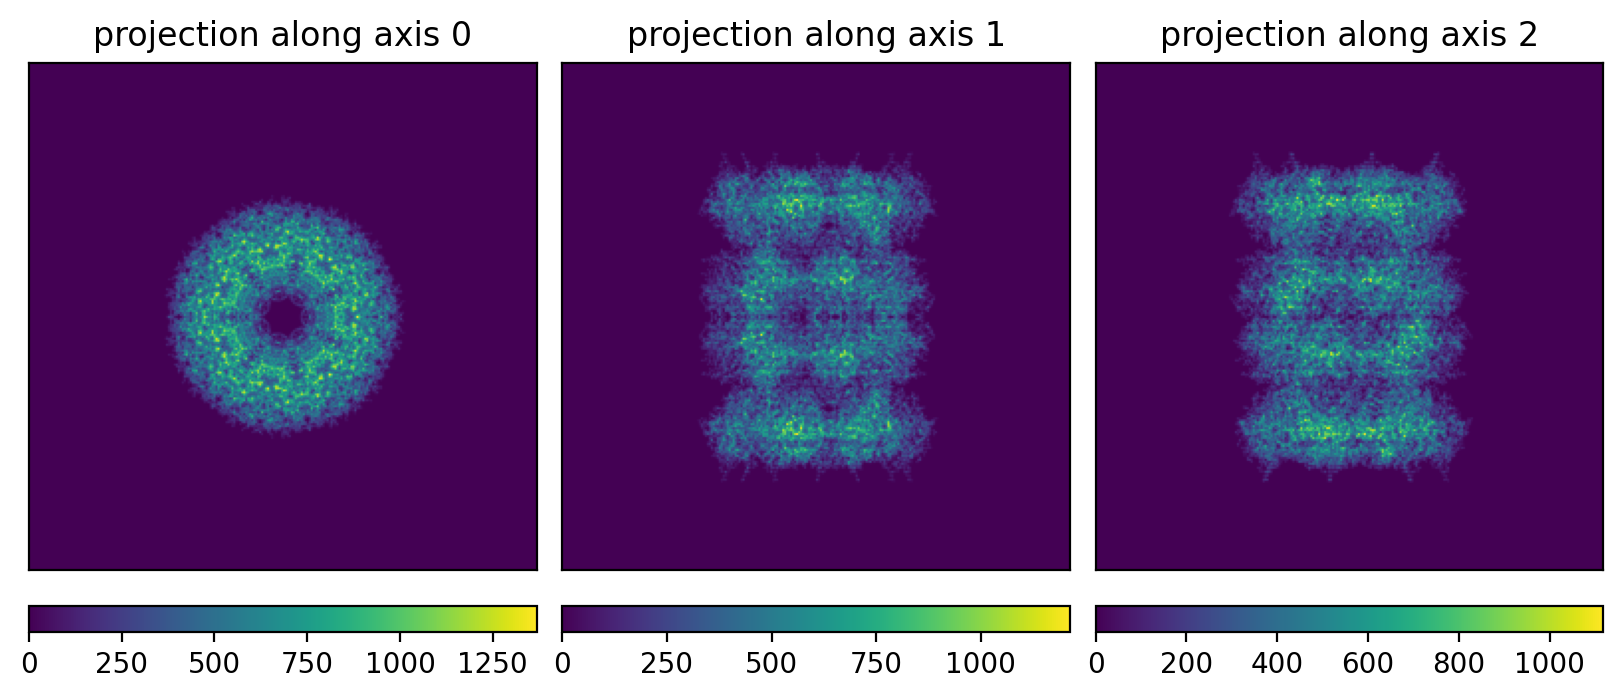

In [6]:
plot3d(V0)

## 3. Pose sampling & volume rotation

Everything from here on operates on a *batch* of particle images, each at
its own orientation, shift and defocus, so before touching ice, crowding or
scattering we need a batch of rotated copies of the density volume built
above. `VolumeRotator` (what `Specimen.scatter` uses for a rendered
template) does exactly this and is just as usable on its own: build an
affine matrix per pose from quaternions and translations via
`specter.rotations`, then call the rotator.

In [7]:
n_particles = config.n_particles

quaternions = rotations.random_quaternion(n_particles)

# random in-plane shift; set config.shift = 0.0 for no shifts
rlnOriginXAngst = 2 * (torch.rand(n_particles) - 0.5) * config.shift
rlnOriginYAngst = 2 * (torch.rand(n_particles) - 0.5) * config.shift
translations = torch.stack([rlnOriginXAngst, rlnOriginYAngst], dim=-1)

nz, ny, nx = V0.shape
rotator = VolumeRotator(nz, ny, nx, origin="relion").to(device)

R = roma.unitquat_to_rotmat(quaternions)
T = rotations.translations_angstrom_to_torch(
    translations, config.n_pixels, config.pixel_size
)
theta = rotations.build_affine_matrix(R, T)

V = rotator(V0.to(device), theta.to(device))
V.shape

torch.Size([4, 256, 256, 256])

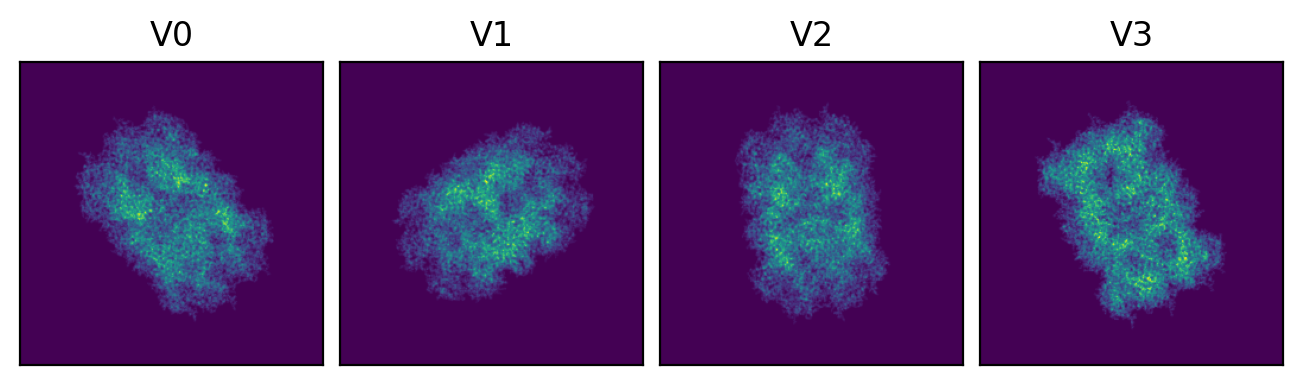

In [8]:
fig, axes = plt.subplots(1, 4, dpi=200, constrained_layout=True)
for i, ax in enumerate(axes.ravel()):
    ax.imshow(V[i].sum(0).cpu())
    ax.set(xticks=[], yticks=[])
    ax.set_title(f"V{i}")
plt.show()

## 4. Padding for FFT / multislice

`nz` may need to grow to accommodate an `ice_thickness` larger than the
particle box, and the XY box is optionally padded to suppress the circular
(wrap-around) convolution artifacts multislice would otherwise produce at
the box edges. `compute_nz`/`pad_volume` are the helpers `Specimen.scatter`
itself calls for this: plain tensor bookkeeping, in `specter.arrays`
alongside SPECTER's other array utilities.

In [9]:
nz_padded = compute_nz(config.n_pixels, config.ice_thickness, config.pixel_size)
V = pad_volume(V, config.n_pixels, nz_padded, config.ice_thickness, config.pad_fft)

pad_nxy = (
    config.n_pixels + (config.n_pixels // 2) * 2 if config.pad_fft else config.n_pixels
)
V.shape

torch.Size([4, 256, 512, 512])

## 5. Molecular crowding (optional)

`CrowdWithDuplicates` places extra Poisson-disk-sampled, randomly rotated
copies of the *same* structure around each particle, simulating a crowded
field of view. It's built once from the original (unrotated, unpadded)
density `V0`, then called once per batch item — mirroring exactly what
`Specimen.scatter` does (`imaging._stages.crowd_into`), just spelled out here instead
of hidden inside it.

In [10]:
crowd_min_distance = (
    config.crowd_min_distance
    if config.crowd_min_distance is not None
    else pdb.max_diameter
)
# The particle BOX's own depth, not nz_padded: the neighbour slab must not
# follow ice_thickness, which is a contrast knob rather than a
# specimen-density one. Mirrors Specimen.crowd's own default.
crowd_max_distance_z = (
    config.crowd_max_distance_z
    if config.crowd_max_distance_z is not None
    else config.n_pixels * config.pixel_size
)

crowd = CrowdWithDuplicates(
    V0.to(device),
    config.pixel_size,
    crowd_min_distance,
    nxy_out=pad_nxy,
    nz_out=nz_padded,
    max_distance_z=crowd_max_distance_z,
    method="3d",
    n_points=torch.inf,
    seed="origin",
    chunk_size=1,
).to(device)

with torch.no_grad():
    for i in range(len(V)):
        V[i] = V[i] + crowd()

Rotating duplicates and insert into micrograph:   0%|          | 0/7 [00:00<?, ?it/s]

Rotating duplicates and insert into micrograph:   0%|          | 0/6 [00:00<?, ?it/s]

Rotating duplicates and insert into micrograph:   0%|          | 0/6 [00:00<?, ?it/s]

Rotating duplicates and insert into micrograph:   0%|          | 0/6 [00:00<?, ?it/s]

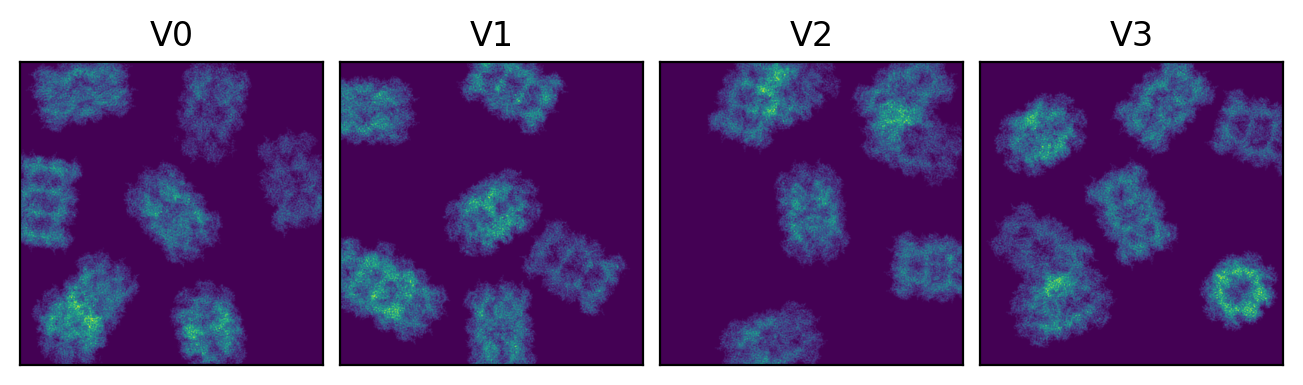

In [11]:
fig, axes = plt.subplots(1, 4, dpi=200, constrained_layout=True)
for i, ax in enumerate(axes.ravel()):
    ax.imshow(V[i].sum(0).cpu())
    ax.set(xticks=[], yticks=[])
    ax.set_title(f"V{i}")
plt.show()

## 6. Amorphous ice solvation

Ice is added only where the structure itself has little density. A
`gd`/`random` icemaker is built via `resolve_icemaker` (the helper
`Specimen.solvate` and `Field.solvate` use to turn an `ice_model` string
into a concrete `IceBank`/`RandomIcemaker`), and blended in with
`blend_ice_into_volume`, which weights the ice by the room each voxel has
left. Both live in `specter.ice`. `Specimen.scatter` blends a slab at a
time to bound memory (`imaging._stages.solvate`); the whole-volume call
below gives the same ice.

In [12]:
icemaker = resolve_icemaker(
    config.ice_model,
    config.pixel_size,
    pad_nxy,
    nz_padded,
    ice_cache_dir=config.ice_cache_dir,
).to(device)

with torch.no_grad():
    V = blend_ice_into_volume(V, icemaker, config.pixel_size)

V.shape

Generating tiled ice volumes:   0%|          | 0/4 [00:00<?, ?it/s]

Placing ice tiles:   0%|          | 0/4 [00:00<?, ?it/s]

Placing ice tiles:   0%|          | 0/4 [00:00<?, ?it/s]

Placing ice tiles:   0%|          | 0/4 [00:00<?, ?it/s]

Placing ice tiles:   0%|          | 0/4 [00:00<?, ?it/s]

torch.Size([4, 256, 512, 512])

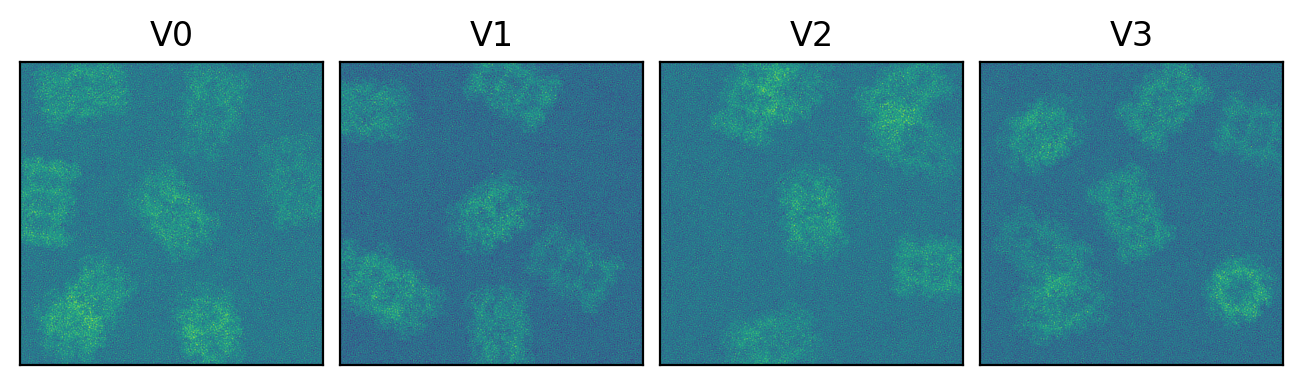

In [13]:
fig, axes = plt.subplots(1, 4, dpi=200, constrained_layout=True)
for i, ax in enumerate(axes.ravel()):
    ax.imshow(V[i].sum(0).cpu())
    ax.set(xticks=[], yticks=[])
    ax.set_title(f"V{i}")
plt.show()

## 7. Electron scattering (multislice)

`Scattering` propagates the complex electron wave through the 3D potential
and returns the 2D exit wave at the specimen's far face — a self-contained
module, parameterized only by box size, pixel size, and beam voltage.

In [14]:
scattering = Scattering(
    pad_nxy,
    config.pixel_size,
    config.voltage,
    scattering_model=config.scattering_model,
    nz=nz_padded,
    alpha=config.alpha,
    oversample=config.oversample,
    crop=False,  # imaged on the propagation grid, see Aberration/Detector below
    progressbars=False,
).to(device)

with torch.no_grad():
    exitwaves = scattering(V)

exitwaves.shape, exitwaves.dtype

(torch.Size([4, 1024, 1024]), torch.complex64)

## 8. Microscope optics / aberrations: the swappable stage

By default, `Aberration` applies defocus and Cs (and any other
transfer-function terms present in `ctf_params`) in Fourier space. One
wrinkle to know about: multislice returns the wave at the volume's *exit
face*, but a CTF defocus value (what a CTF fit reports and CryoSPARC/RELION
record) is the defocus of the specimen's *midplane*, half the volume's depth
above it. `ExitWave` carries that offset and `ExitWave.apply_ctf` subtracts
it; `specter.aberrations.defocus_midplane_shift`
is the public function it is built on, so composing this by hand doesn't
mean re-deriving the correction yourself.

`bfactor` is the one CTF term that's also a constructor kwarg here: since
it's usually one global calibration value for a whole batch rather than
something that genuinely varies per particle (unlike `dfu`/`cs`), it can be
given once. If given, it overrides any `"bfactor"` already in `ctf_params`,
the same precedence `ExitWave.apply_ctf(bfactor=...)` and `Reconstructor`
use.

In [15]:
cs_angstrom = config.cs * 1e7  # mm -> Å

defocus_low, defocus_high = parse_scalar_or_range(config.defocus)
defocus_angstrom = torch.rand(n_particles) * (defocus_high - defocus_low) + defocus_low
# the wave leaves the exit face; the nominal defocus is the midplane's
defocus_shift_angstrom = defocus_midplane_shift(nz_padded, config.pixel_size)
dfu = defocus_angstrom - defocus_shift_angstrom

ctf_params = {
    "cs": torch.full((n_particles,), cs_angstrom),
    "dfu": dfu,
}

# Not user-configurable independently of scattering_model -- see
# aberrations.aberration_model_for_scattering.
aberration_model = aberration_model_for_scattering(config.scattering_model)

# On the propagation grid (oversample times finer than the pixels): the
# intensity has twice the wave's bandwidth, and the detector samples it down.
aberration = Aberration(
    pad_nxy * config.oversample,
    config.pixel_size / config.oversample,
    config.voltage,
    aberration_model=aberration_model,
    alpha=config.alpha,
    bfactor=config.bfactor,
).to(device)

ctf_params_gpu = {k: v.to(device) for k, v in ctf_params.items()}
with torch.no_grad():
    detector_waves = aberration(exitwaves, ctf_params_gpu)

detector_waves.shape

torch.Size([4, 1024, 1024])

## 9. Detector physics

`Detector` converts the (possibly aberrated) exit wave to an intensity
image, applying dose scaling, optional MTF, and Poisson noise. It only
needs the exit wave, dose, and coincidence radius — it has no idea whether
the wave came from `Aberration` or the hand-rolled version above.

In [16]:
from specter.aberrations import FocalSpread
from specter.constants import energy_to_wavelength

dose_low, _ = parse_scalar_or_range(config.dose)
dose_batch = torch.full((n_particles,), dose_low, device=device)
coincidence_radius_low, _ = parse_scalar_or_range(config.coincidence_radius)
coincidence_radius = torch.full((n_particles,), coincidence_radius_low, device=device)

# dose-fractionated coincidence loss (coincidence_radius > 0) needs n_frames;
# fall back to one frame per unit dose, same convention as create_particle_stack.
n_frames = config.n_frames if config.n_frames is not None else int(dose_low)

# The Cc focal spread (on by default; cc = 0 disables it), summed over at the
# detector rather than applied to the CTF as an envelope, which is exact only
# for the part of the image linear in the scattered wave.

focal_spread = (
    FocalSpread.from_instrument(
        config.cc * 1e7,
        config.voltage * 1e3,
        config.energy_spread,
        config.deltaV_V,
        config.deltaI_I,
        energy_to_wavelength(config.voltage),
    )
    if config.cc and aberration_model == "nonlinear"
    else None
)

detector = Detector(
    config.pixel_size,
    aberration_model=aberration_model,
    noise_model=config.noise_model,
    mtf=None,  # config.detector_model == "none"; swap in specter.detectors.k3_300kv(...) etc. otherwise
    n_frames=n_frames,
    oversample=config.oversample,
    focal_spread=focal_spread,
).to(device)

with torch.no_grad():
    images = detector(
        detector_waves, dose_batch, coincidence_radius, nxy=config.n_pixels
    )

images.shape

torch.Size([4, 256, 256])

## 10. Visualize

Both stacks — the stock `Aberration` model and the hand-rolled custom
transfer function — went through identical density/ice/crowding/scattering
and the same `Detector` call. The only difference is the extra phase ramp
injected in section 8, visible here as fringes on top of the usual
defocus-driven contrast.

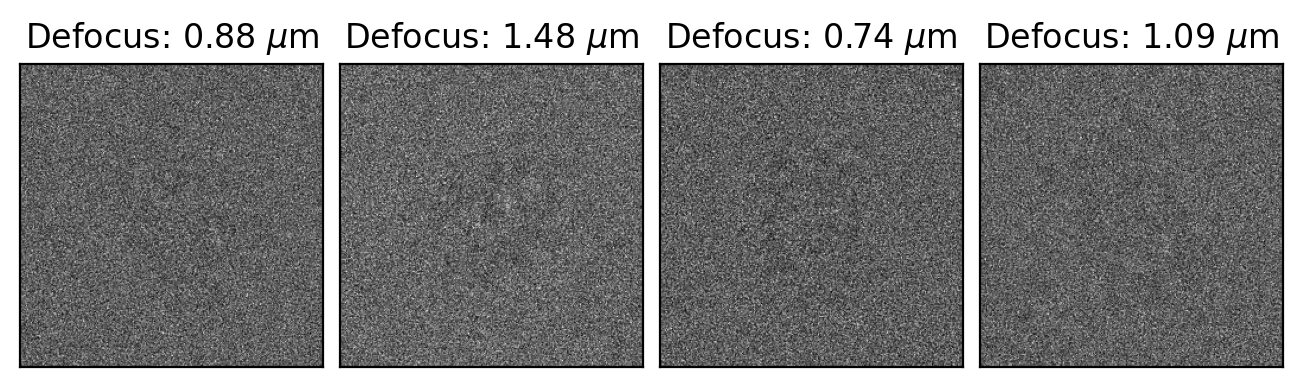

In [17]:
images_cpu = images.detach().cpu()

fig, axes = plt.subplots(1, n_particles, dpi=200, constrained_layout=True)
for i in range(n_particles):
    ax = axes[i]
    ax.imshow(images_cpu[i], cmap="grey")
    ax.set(xticks=[], yticks=[])
    ax.set_title(rf"Defocus: {defocus_angstrom[i] / 10000:.2f} $\mu$m")

plt.show()

## 11. Normalize
Particles in cryo-EM are typically inverted (white particles on black background), mean-centered, and normalized to std = 1.

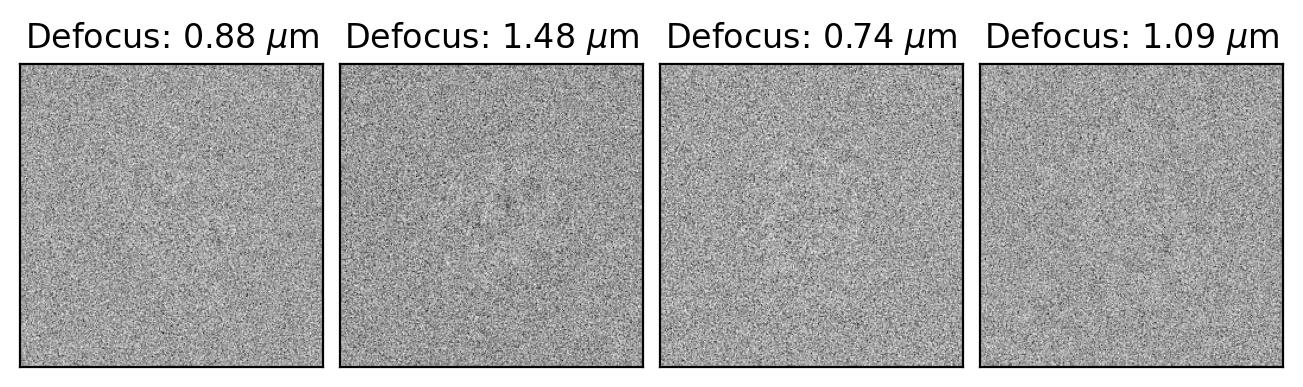

In [18]:
particles, means, stds = normalize_particles(images_cpu)
particles = -particles

fig, axes = plt.subplots(1, n_particles, dpi=200, constrained_layout=True)
for i, ax in enumerate(axes.ravel() if n_particles > 1 else [axes]):
    ax.imshow(particles[i], cmap="grey")
    ax.set(xticks=[], yticks=[])
    ax.set_title(rf"Defocus: {defocus_angstrom[i] / 10000:.2f} $\mu$m")
plt.show()